# Statistical Analysis | Washington Housing Analysis

In [4]:
# Import pandas, numpy, and matplotlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# seaborn is a data visualization library built on matplotlib
import seaborn as sns

In [5]:
from pathlib import Path

DATA_DIR = Path('../data')

final_dataset_path = DATA_DIR / 'housing_final.csv'

df = pd.read_csv(final_dataset_path  , dtype = {'county_fips': str})

## Relationship between Home Value and Median Income

### Research Question
Is median household income significantly associated with county-level home values in Washington State?

$H_0$: The regression coefficient for median household income equals zero $(\beta_1 = 0)$.

$H_A$: The regression coefficient for median household income does not equal zero $(\beta_1 \ne 0)$.

### Method
Oridnary Least Squares (OLS)

We first fit the original model in dollars (Model 1), then correct three problems:

1. **Non-independent observations.** Each county appears 10 times (once per year), so rows are not independent and standard OLS p-values are too small. We use standard errors **clustered by county**.
2. **Errors grow with home value.** We model `log(home value)` on `log(income)`, so the coefficient is an elasticity (percent change in value for a 1% change in income) and the errors are more even.
3. **Differences between counties.** Income and home values both differ a lot between counties for reasons we do not measure. A model with county fixed effects (Model 3) looks at changes within each county over time.

In [6]:
import statsmodels.formula.api as smf
from statsmodels.stats.stattools import durbin_watson

model_df = df.dropna(subset=["average_zhvi", "median_income"]).copy()
model_df["log_zhvi"] = np.log(model_df["average_zhvi"])
model_df["log_income"] = np.log(model_df["median_income"])
print(model_df.shape)

(389, 10)


### Model 1: Original model (dollars, standard OLS errors)

In [7]:
model_1 = smf.ols("average_zhvi ~ median_income", data=model_df).fit()
print(model_1.summary())

                            OLS Regression Results                            
Dep. Variable:           average_zhvi   R-squared:                       0.712
Model:                            OLS   Adj. R-squared:                  0.711
Method:                 Least Squares   F-statistic:                     956.2
Date:                Sun, 22 Nov 2026   Prob (F-statistic):          1.28e-106
Time:                        14:13:21   Log-Likelihood:                -4942.1
No. Observations:                 389   AIC:                             9888.
Df Residuals:                     387   BIC:                             9896.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept     -1.754e+05   1.71e+04    -10.241

* The p-value is less than our significance level of 0.05 hence we reject $H_0$.
* The regression coefficient ($\beta_1$) for median household income is 8.1776.
* A `$10,000` Dollar increase in household income explains approximately `$81,776` increase in home value.
* The $R^2$ value of 0.712 indicates that the median income explains approximately 71.2% of the observed variations in the given home values.
* **Problem:** the Durbin-Watson statistic is about 0.27 (values near 2 are healthy), which signals strong autocorrelation. The same counties repeat every year, so the p-value above is overstated. Model 2 corrects this.

### Model 2: Log-log model with county-clustered standard errors

In [8]:
model_2 = smf.ols("log_zhvi ~ log_income", data=model_df).fit(
    cov_type="cluster", cov_kwds={"groups": model_df["county_fips"]}
)
print(model_2.summary().tables[1])
print(f"\nR-squared: {model_2.rsquared:.3f} | residual SD (log): {np.sqrt(model_2.mse_resid):.3f}")

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -4.3247      0.914     -4.730      0.000      -6.117      -2.533
log_income     1.5397      0.082     18.666      0.000       1.378       1.701

R-squared: 0.723 | residual SD (log): 0.221


In [9]:
b = model_2.params["log_income"]; lo, hi = model_2.conf_int().loc["log_income"]
print(f"A 1% higher median income is associated with a {b:.2f}% higher home value (95% CI {lo:.2f}% to {hi:.2f}%)")
print(f"Doubling income (+100%) is associated with a {(2 ** b - 1) * 100:.0f}% higher home value")

A 1% higher median income is associated with a 1.54% higher home value (95% CI 1.38% to 1.70%)
Doubling income (+100%) is associated with a 191% higher home value


* We still reject $H_0$ at the 0.05 level (cluster-robust p-value), so income is associated with home values. The standard errors now account for repeated observations from the same county. (They are not comparable with Model 1's, because the two models use different units.)
* The coefficient is an elasticity: a 1% higher income is associated with roughly a 1.5% higher home value. This compares counties of different sizes on a percentage basis.
* This is an association, not proof that income causes higher home values. Counties with higher incomes differ in many other ways.

### Model 3: Adding county fixed effects

In [10]:
model_3 = smf.ols("log_zhvi ~ log_income + C(county_fips)", data=model_df).fit(
    cov_type="cluster", cov_kwds={"groups": model_df["county_fips"]}
)
print(f"log_income coefficient: {model_3.params['log_income']:.3f} (SE {model_3.bse['log_income']:.3f}, p = {model_3.pvalues['log_income']:.4f})")
print(f"R-squared: {model_3.rsquared:.3f} | residual SD (log): {np.sqrt(model_3.mse_resid):.3f}")

# Autocorrelation of residuals within each county (near 2 is healthy)
for name, m in [("Model 2", model_2), ("Model 3", model_3)]:
    dw = pd.Series(m.resid.values, index=model_df.index).groupby(model_df["county_fips"]).apply(lambda s: durbin_watson(s.values)).mean()
    print(f"{name}: mean within-county Durbin-Watson = {dw:.2f}")

log_income coefficient: 1.681 (SE 0.050, p = 0.0000)
R-squared: 0.961 | residual SD (log): 0.087
Model 2: mean within-county Durbin-Watson = 0.32
Model 3: mean within-county Durbin-Watson = 0.78


* With county fixed effects, the coefficient measures how a county's home values move when its own income changes over time, and not differences between counties.
* The coefficient (about 1.68) is close to Model 2 (about 1.54), so the relationship also holds within counties over time. Because both income and home values trend upward and are in nominal dollars, part of this still reflects the shared time trend (notebook 04 tests this by adding year effects).
* The Durbin-Watson values show whether autocorrelation remains. Values well below 2 mean residuals from one year still predict the next, so even clustered standard errors deserve some caution.

In [17]:
compare = pd.DataFrame({
    "Model 1: dollars, OLS": {"income coef": f"{model_1.params['median_income']:.3f}", "SE": f"{model_1.bse['median_income']:.3f}", "p": f"{model_1.pvalues['median_income']:.4f}", "R-squared": f"{model_1.rsquared:.3f}"},
    "Model 2: log-log, clustered": {"income coef": f"{model_2.params['log_income']:.3f}", "SE": f"{model_2.bse['log_income']:.3f}", "p": f"{model_2.pvalues['log_income']:.4f}", "R-squared": f"{model_2.rsquared:.3f}"},
    "Model 3: + county FE": {"income coef": f"{model_3.params['log_income']:.3f}", "SE": f"{model_3.bse['log_income']:.3f}", "p": f"{model_3.pvalues['log_income']:.4f}", "R-squared": f"{model_3.rsquared:.3f}"},
})
compare

,"Model 1: dollars, OLS","Model 2: log-log, clustered",Model 3: + county FE
income coef,8.178,1.540,1.681
SE,0.264,0.082,0.050
p,0.0000,0.0000,0.0000
R-squared,0.712,0.723,0.961


Review actual vs predicted home value

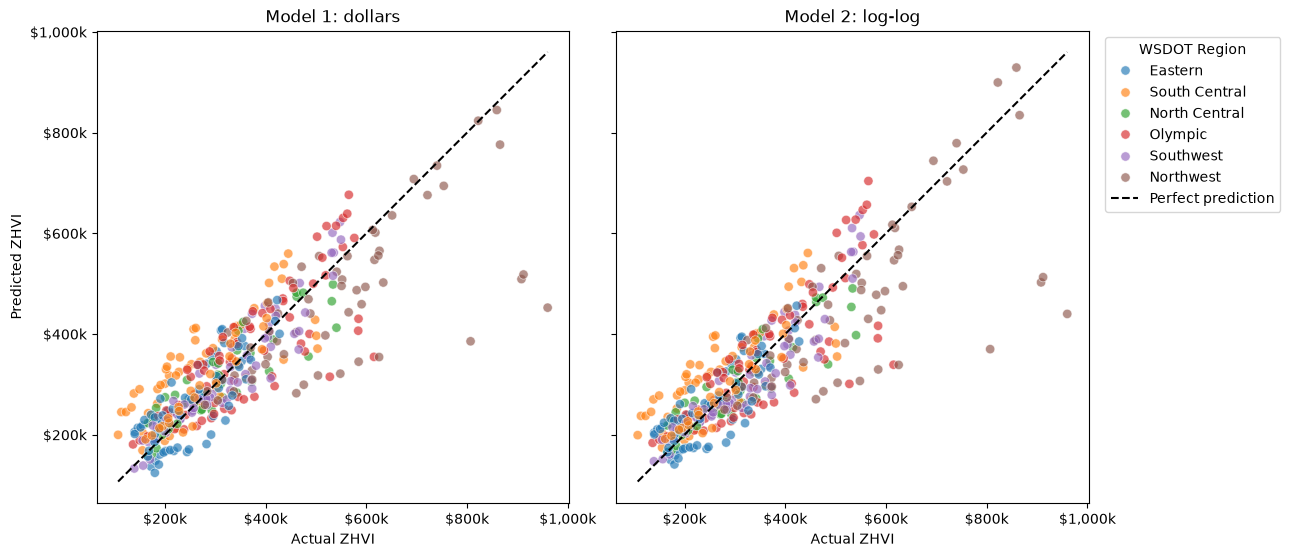

In [11]:
model_df["pred_m1"] = model_1.predict(model_df)
model_df["pred_m2"] = np.exp(model_2.predict(model_df))      # back-transform to dollars

from matplotlib.ticker import FuncFormatter
money_fmt = FuncFormatter(lambda x, pos: f"${x/1000:,.0f}k")
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharex=True, sharey=True)
axis_min, axis_max = model_df["average_zhvi"].min(), model_df["average_zhvi"].max()
for ax, col, title in zip(axes, ["pred_m1", "pred_m2"], ["Model 1: dollars", "Model 2: log-log"]):
    sns.scatterplot(data=model_df, x="average_zhvi", y=col, hue="wsdot_region", alpha=0.65, s=45, ax=ax, legend=(ax is axes[1]))
    ax.plot([axis_min, axis_max], [axis_min, axis_max], "k--", label="Perfect prediction")
    ax.set(title=title, xlabel="Actual ZHVI", ylabel="Predicted ZHVI"); ax.set_aspect("equal", adjustable="box")
    ax.xaxis.set_major_formatter(money_fmt); ax.yaxis.set_major_formatter(money_fmt)
axes[1].legend(title="WSDOT Region", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

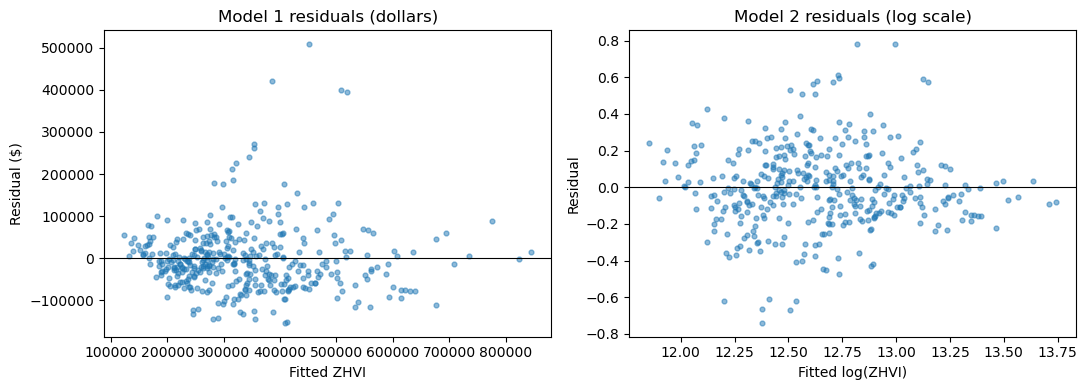

In [20]:
# Do errors still grow with home value?
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(model_1.fittedvalues, model_1.resid, s=12, alpha=0.5); axes[0].set(title="Model 1 residuals (dollars)", xlabel="Fitted ZHVI", ylabel="Residual ($)")
axes[1].scatter(model_2.fittedvalues, model_2.resid, s=12, alpha=0.5); axes[1].set(title="Model 2 residuals (log scale)", xlabel="Fitted log(ZHVI)", ylabel="Residual")
for a in axes: a.axhline(0, color="k", lw=0.8)
plt.tight_layout(); plt.show()

* In Model 1 the residuals are skewed and curved: several large positive misses at mid-range values, and consistent negative misses for the highest values. A straight line in dollars fits poorly. The log model (Model 2) has residuals that are more evenly spread around zero.
* The predictions still follow a clear pattern by region, so income alone does not capture everything about home values. The multiple regression in notebook 04 adds unemployment and mortgage rates and county and year effects.

### Limitations
* Median income and ZHVI are both in nominal dollars, not adjusted for inflation, so part of the relationship reflects general price increases over time. A CPI adjustment (for example the BLS CPI-U) would address this.
* Model 3 controls for fixed differences between counties but not for common shocks in each year (see notebook 04, which adds year effects).
* Results show association, not causation.